# The goal:

     => I need to understand de impact of detrending in the outier idenfication

1. I dentifie the outliers (RFI);
2. Perform the statical analysis (Std, MAD, Skewnss, kurtosis), off source, on source and after source;
3. Perform detreding;
4. Perform statical analysis (Std, MAD, Skewnss, kurtosis), off source, on source and after source;
5. Compare the resuts.


In [1]:
# import the libraries
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import cm, colors as mcolors



import scienceplots
plt.style.use(['science', 'no-latex'])


from pybaselines import Baseline, utils 
from scipy.signal import find_peaks
from scipy.stats import skew, kurtosis, gaussian_kde
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models


# Read and convert it to xarray

In [2]:
filename = ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5')


# Let's porint the structure of the hdf5 file
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

with h5py.File(filename, "r") as f:

    f.visititems(print_hdf5_structure)

    f.close()  # close the file



Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
Group: monitor
  Group: monitor/acu
    Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
    Group: monitor/acu/ambient_temp_correction_config
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_2, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_3, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_4, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_5a, Shape: (2650,), Dtype: float64
      Dataset:

In [3]:

# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]


datasets = []

with h5py.File(filename, 'r') as f:
    for g in groups:
        
        # Load datasets correctly
        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]       # shape (n_time, n_freq)
        frequency = f[f"{g}/frequency"][1600:-60]/ 1e9
        time      = f[f"{g}/timestamp"][30:,0]     # often 2D


        # Construct xarray dataset
        ds = xr.Dataset(
            {
                "spectrum": (("time", "frequency"), spectrum)
            },
            coords={
                "time": time,
                "frequency": frequency
            },
            attrs={
                "description": f"Spectrum data of {g}",
                "units": {
                    "spectrum": "dB",
                    "frequency": "GHz",
                    "time": "UTC"
                }
            }
        )

        ds = ds.expand_dims({"group": [g]})  # add group dimension

        datasets.append(ds)
    f.close() # close the file

datasets

[<xarray.Dataset> Size: 163MB
 Dimensions:    (group: 1, time: 634, frequency: 63877)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND0'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 1.883e+11 ... 4.159e+09
 Attributes:
     description:  Spectrum data of scan/000/P1_ND0
     units:        {'spectrum': 'dB', 'frequency': 'GHz', 'time': 'UTC'},
 <xarray.Dataset> Size: 163MB
 Dimensions:    (group: 1, time: 634, frequency: 63877)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND1'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 6.967e+10 ... 1.648e+09
 Attributes:
     description:  Spectrum da

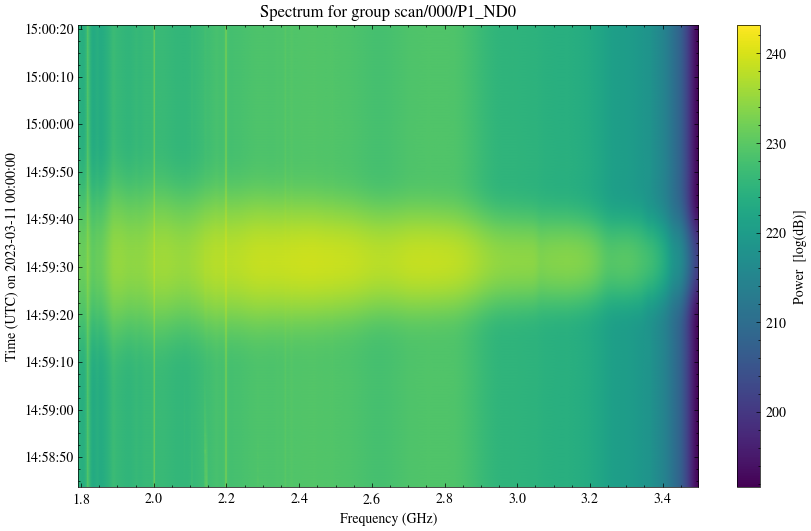

In [4]:
# define the variablues

for i,g in enumerate(datasets):
    spectrum = (10*np.log10(datasets[i]['spectrum']**2)).values[0, :,:]
    time = datasets[i]['time'].values
    frequency = datasets[i]['frequency'].values

    # Date
    time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)
    date =  pd.to_datetime(time_utc[0].strftime('%Y-%m-%d'))
    plt.figure(figsize=(10, 6))

    plt.imshow(spectrum, aspect='auto', 
    extent=[frequency[0], frequency[-1], time_utc[0], time_utc[-1]],
    origin='lower', cmap='viridis')

    plt.colorbar(label='Power  [log(dB)]')
    plt.ylabel(f'Time (UTC) on {date}')
    plt.xlabel('Frequency (GHz)')
    plt.title(f'Spectrum for group {datasets[i].group.values[0]}')
    plt.show()

    break

In [5]:
# Define the three bookshelves  

timebookshelves = pd.to_datetime(["2023-03-11 14:59:00+00:00",
                                  "2023-03-11 14:59:30+00:00",
                                  "2023-03-11 15:00:00+00:00"])


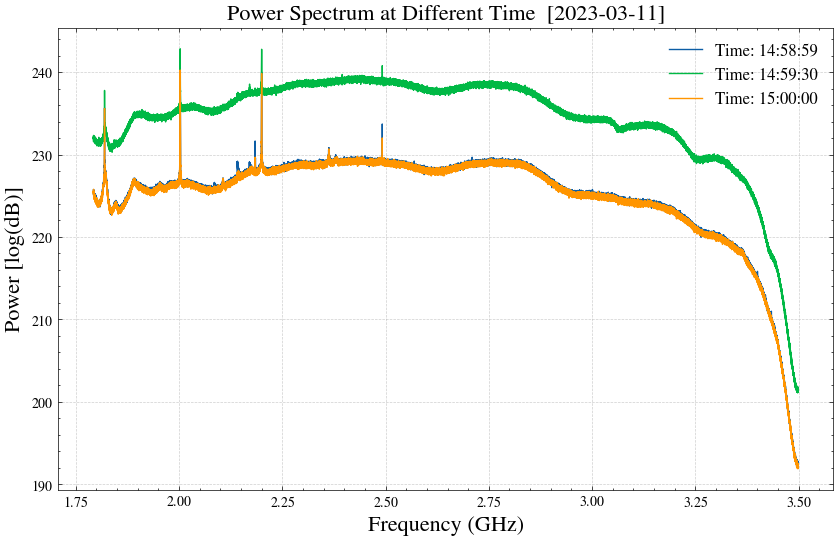

In [6]:
# find nearest time index
itime = time_utc.get_indexer(timebookshelves, method='nearest')
#itime

# #extract the spectrum at the nearest time index


plt.figure(figsize=(10, 6))
for t in itime:
    spectrum_source = spectrum[t, :]
    plt.plot(frequency, spectrum_source, label=f'Time: {time_utc[t].strftime("%H:%M:%S")}')

plt.xlabel('Frequency (GHz)', fontsize=16)
plt.ylabel('Power [log(dB)]', fontsize=16)
plt.title(f'Power Spectrum at Different Time  [{time_utc[0].strftime("%Y-%m-%d")}]', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)


#plt.savefig(f'det_asls_plots/Power_Spectrum_at_Different_Time_Points.png', dpi=300, bbox_inches='tight')

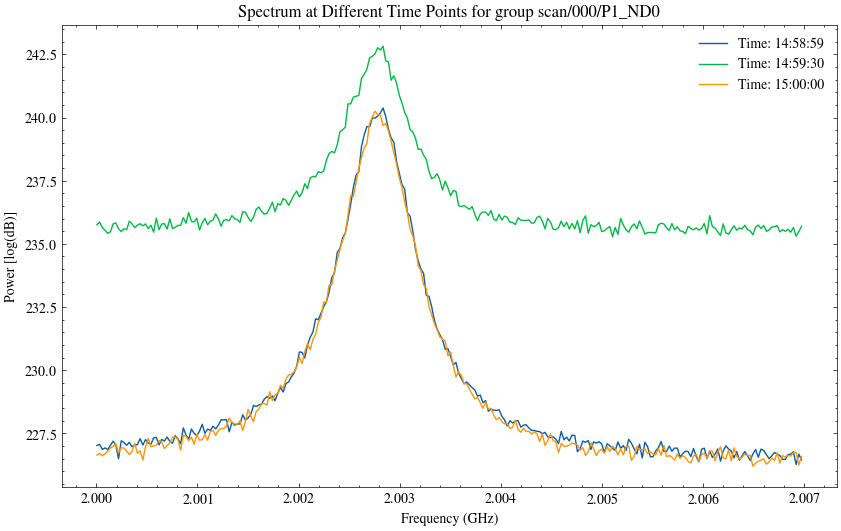

In [7]:
# Isolate the skipe 2 GHz 
mask = (frequency > 2.00) & (frequency < 2.007)


plt.figure(figsize=(10, 6))
for t in itime:
    spectrum_source = spectrum[t, mask]
    plt.plot(frequency[mask], spectrum_source, label=f'Time: {time_utc[t].strftime("%H:%M:%S")}')


plt.xlabel('Frequency (GHz)')
plt.ylabel('Power [log(dB)]')
plt.title(f'Spectrum at Different Time Points for group {datasets[i].group.values[0]}')
plt.legend()

# Statical Analysis befero detrending

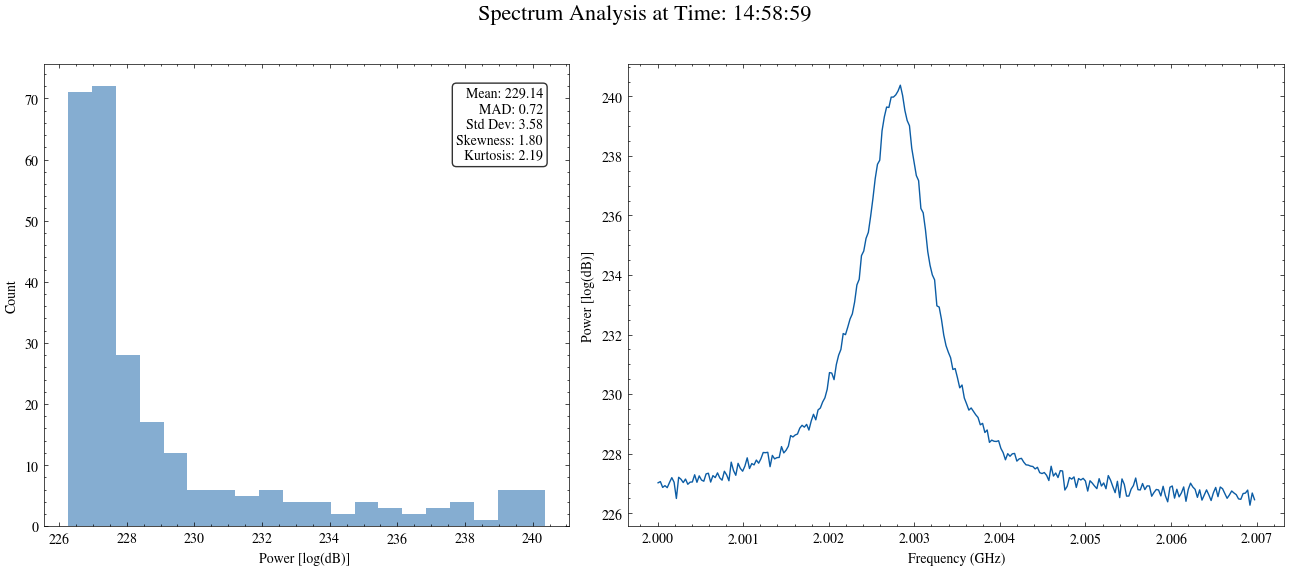

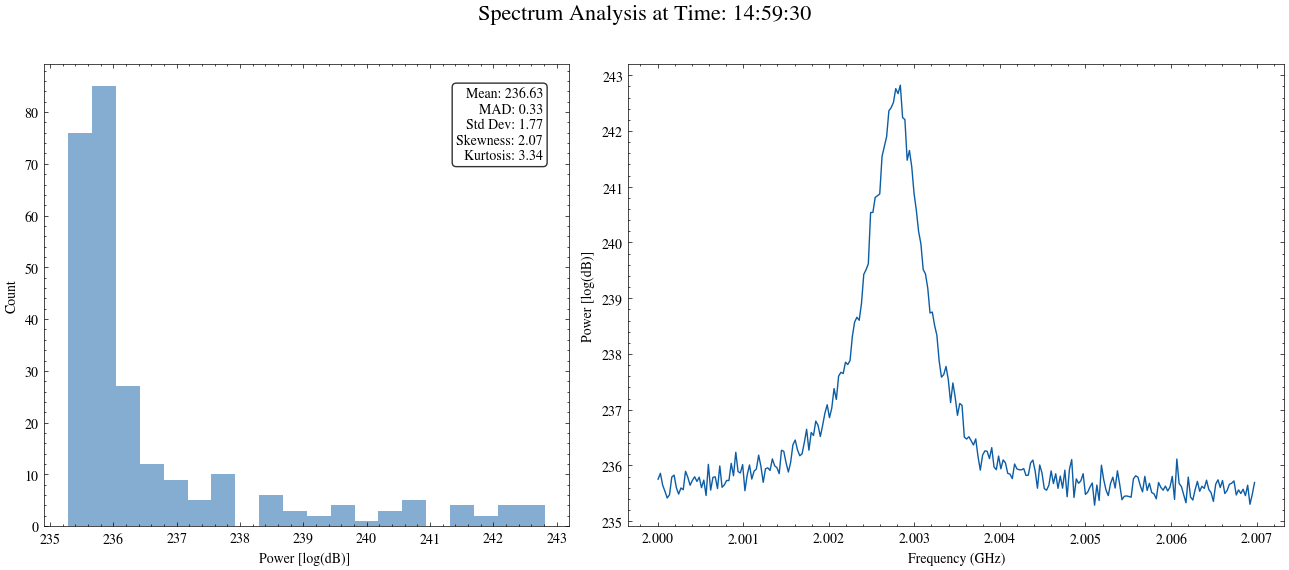

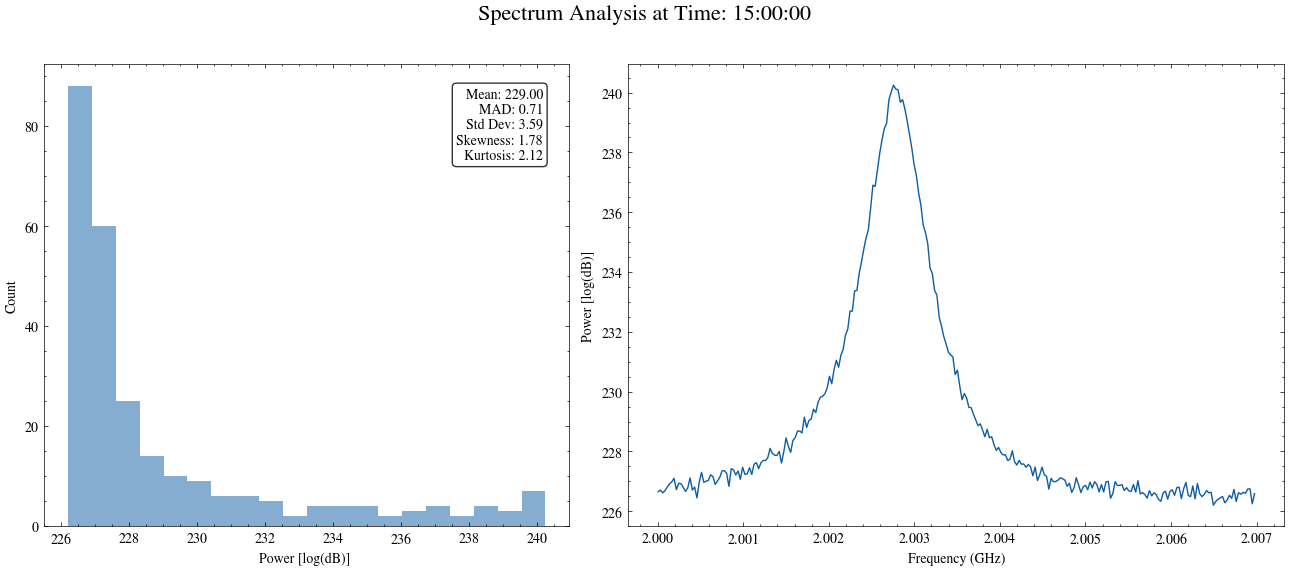

In [8]:
rows = []

for t in itime:
    #statical parameters
    mean = np.mean(spectrum[t, mask])
    mad = MAD(spectrum[t, mask])
    std_dev = np.std(spectrum[t, mask])
    skewness = skew(spectrum[t, mask])
    kurt = kurtosis(spectrum[t, mask])

    #create a dataframe to hold the statistics
    rows.append({
        'Time': time_utc[t].strftime("%H:%M:%S"),
        'Mean': mean,
        'MAD': mad,
        'Std Dev': std_dev,
        'Skewness': skewness,
        'Kurtosis': kurt
    })
    stats_df = pd.DataFrame(rows)

    fig = plt.figure(figsize=(16, 6))
    plt.suptitle(f'Spectrum Analysis at Time: {time_utc[t].strftime("%H:%M:%S")}', fontsize=16)
    gs = fig.add_gridspec(1, 2, width_ratios=[2, 2.5], 
                          height_ratios=[1], wspace=0.1, hspace=0.3)
    
    stats_text = (f"Mean: {mean:.2f}\n"
                  f"MAD: {mad:.2f}\n"
                  f"Std Dev: {std_dev:.2f}\n"
                  f"Skewness: {skewness:.2f}\n"
                  f"Kurtosis: {kurt:.2f}")

    ax0 = fig.add_subplot(gs[0, 0])
    ax0.hist(spectrum[t, mask], bins=20, alpha=0.5)
    ax0.set_xlabel('Power [log(dB)] ')
    ax0.set_ylabel('Count')
    ax0.text(0.95, 0.95, stats_text, transform=ax0.transAxes, fontsize=10,
             verticalalignment='top', horizontalalignment='right',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    ax1 = fig.add_subplot(gs[0, 1])
    ax1.plot(frequency[mask],spectrum[t, mask])
    ax1.set_ylabel('Power [log(dB)]')
    ax1.set_xlabel('Frequency (GHz)')


In [9]:
stats_df

,Time,Mean,MAD,Std Dev,Skewness,Kurtosis
0,14:58:59,229.140732,0.723137,3.582800,1.803448,2.187332
1,14:59:30,236.634537,0.326195,1.767075,2.069404,3.338114
2,15:00:00,229.000275,0.705399,3.585181,1.784057,2.117660


# Detrendig 

In [10]:
# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline

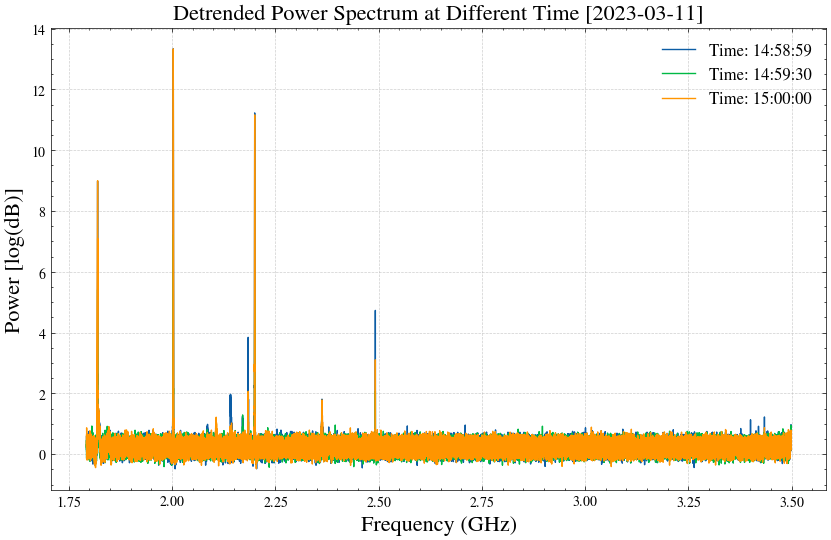

In [11]:
# #extract the spectrum at the nearest time index

plt.figure(figsize=(10, 6))
for t in list(itime):
    spectrum_bcorrected = base_correction(frequency, spectrum[t, :])
    
    plt.plot(frequency, spectrum_bcorrected, label=f'Time: {time_utc[t].strftime("%H:%M:%S")}')
    

plt.xlabel('Frequency (GHz)',fontsize=16)
plt.ylabel('Power [log(dB)]',fontsize=16)
plt.title(f'Detrended Power Spectrum at Different Time [{time_utc[0].strftime("%Y-%m-%d")}]',fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#plt.savefig(f'det_asls_plots/Detrended_Power_Spectrum_at_Different_Time_{time_utc[0].strftime("%Y-%m-%d")}.png', dpi=300, bbox_inches='tight')

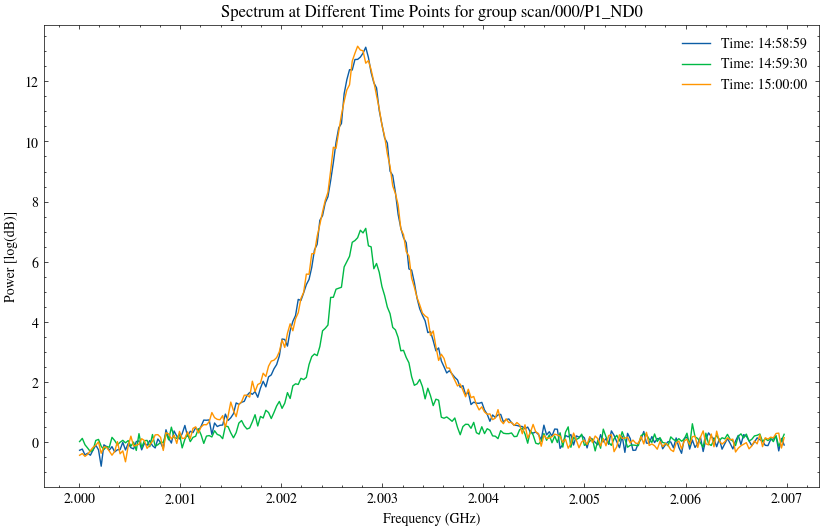

In [12]:
# #extract the spectrum at the nearest time index

detrended_spectra = []
plt.figure(figsize=(10, 6))
for t in list(itime):
    spectrum_bcorrected = base_correction(frequency[mask], spectrum[t, mask])
    detrended_spectra.append(spectrum_bcorrected)
    
    plt.plot(frequency[mask], spectrum_bcorrected, label=f'Time: {time_utc[t].strftime("%H:%M:%S")}')
    

plt.xlabel('Frequency (GHz)')
plt.ylabel('Power [log(dB)]')
plt.title(f'Spectrum at Different Time Points for group {datasets[i].group.values[0]}')
plt.legend()

# Statical Analyses after detrending

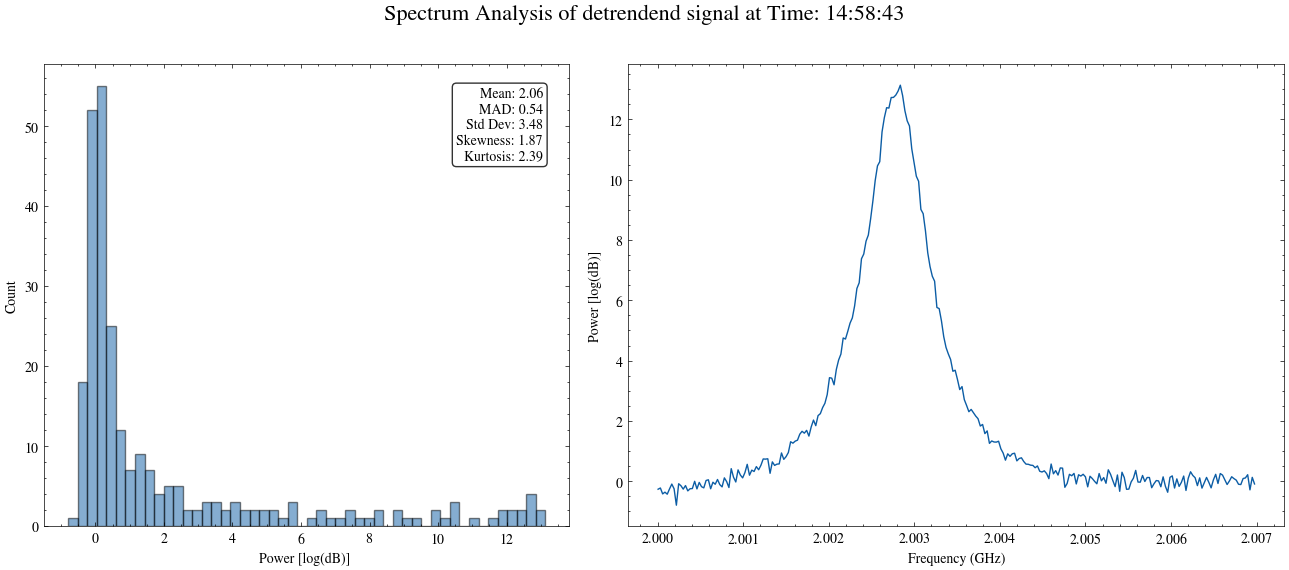

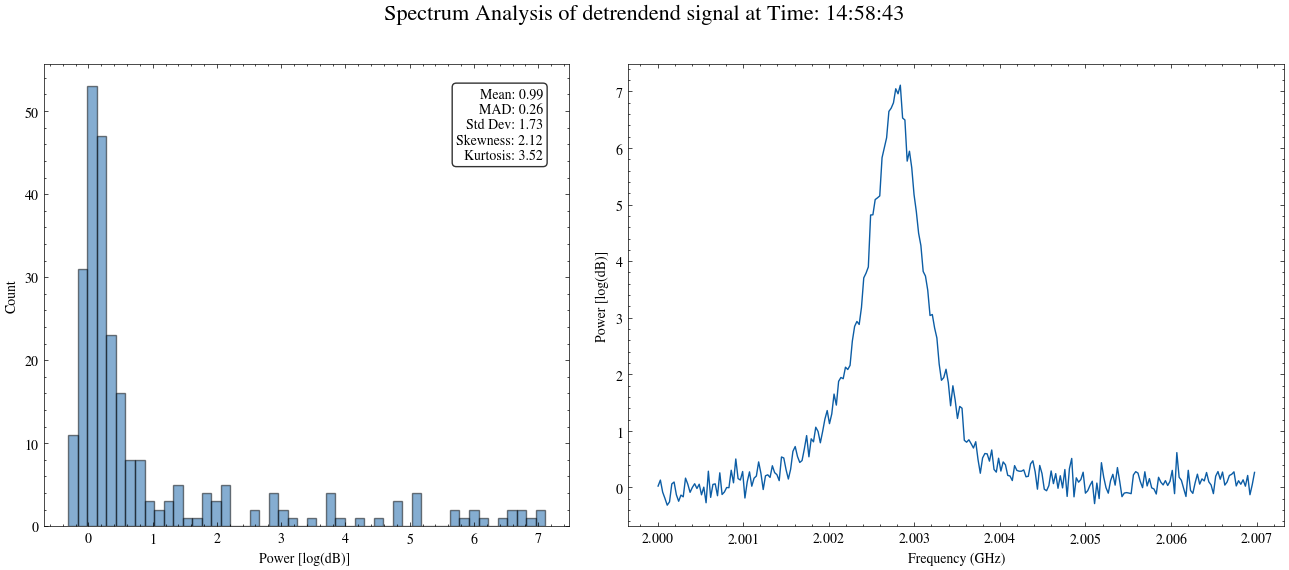

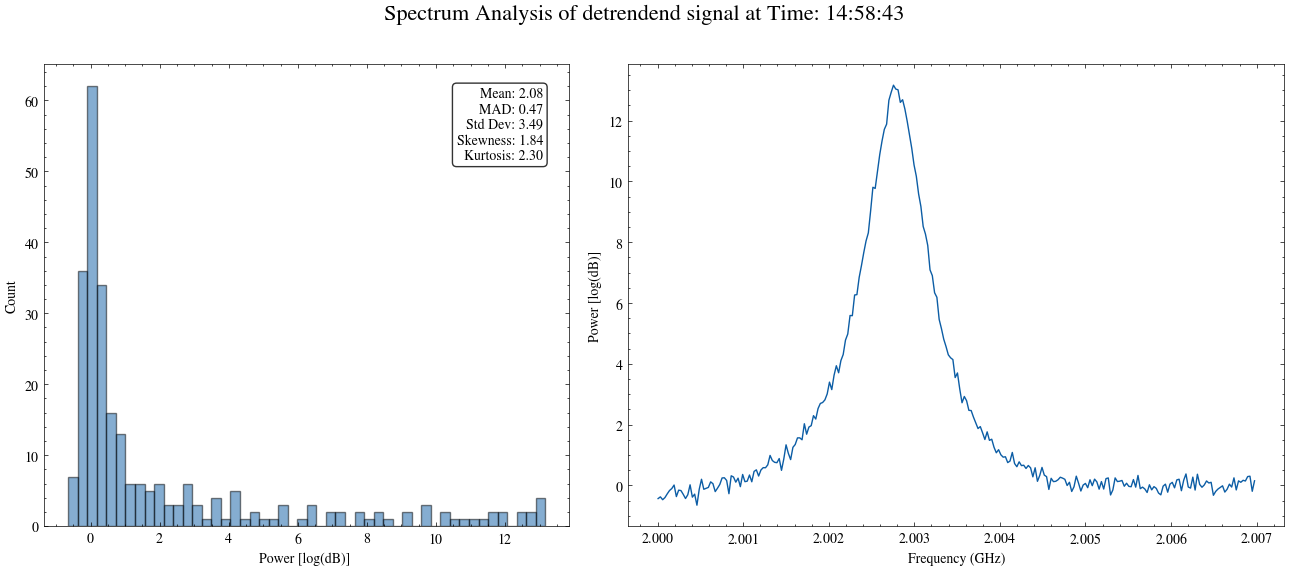

In [13]:
rows = []
for t in range(len(detrended_spectra)):
    #statical parameters
    mean = np.mean(detrended_spectra[t])
    mad = MAD(detrended_spectra[t])
    std_dev = np.std(detrended_spectra[t])
    skewness = skew(detrended_spectra[t])
    kurt = kurtosis(detrended_spectra[t])


    # create a dataframe to hold the statistics
    rows.append({
        'Time': time_utc[itime[t]].strftime("%H:%M:%S"),
        'Mean_det': mean,
        'MAD_det': mad,
        'Std Dev_det': std_dev,
        'Skewness_det': skewness,
        'Kurtosis_det': kurt
    })
    stats_df_det = pd.DataFrame(rows)



    fig = plt.figure(figsize=(16, 6))
    plt.suptitle(f'Spectrum Analysis of detrendend signal at Time: {time_utc[t].strftime("%H:%M:%S")}', fontsize=16)
    gs = fig.add_gridspec(1, 2, width_ratios=[2, 2.5], 
                          height_ratios=[1], wspace=0.1, hspace=0.3)
    
    stats_text = (f"Mean: {mean:.2f}\n"
                  f"MAD: {mad:.2f}\n"
                  f"Std Dev: {std_dev:.2f}\n"
                  f"Skewness: {skewness:.2f}\n"
                  f"Kurtosis: {kurt:.2f}")

    ax0 = fig.add_subplot(gs[0, 0])
    ax0.hist(detrended_spectra[t], bins=50, alpha=0.5, edgecolor='black')
    ax0.set_xlabel('Power [log(dB)] ')
    ax0.set_ylabel('Count')
    ax0.text(0.95, 0.95, stats_text, transform=ax0.transAxes, fontsize=10,
             verticalalignment='top', horizontalalignment='right',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    ax1 = fig.add_subplot(gs[0, 1])
    ax1.plot(frequency[mask],detrended_spectra[t])
    ax1.set_ylabel('Power [log(dB)]')
    ax1.set_xlabel('Frequency (GHz)')


# Camper the results

In [14]:
stats_df_det

,Time,Mean_det,MAD_det,Std Dev_det,Skewness_det,Kurtosis_det
0,14:58:59,2.063246,0.539215,3.482678,1.869106,2.390088
1,14:59:30,0.992371,0.264023,1.730365,2.117664,3.518888
2,15:00:00,2.081160,0.474899,3.490592,1.843887,2.304063


In [15]:
stats_df

,Time,Mean,MAD,Std Dev,Skewness,Kurtosis
0,14:58:59,229.140732,0.723137,3.582800,1.803448,2.187332
1,14:59:30,236.634537,0.326195,1.767075,2.069404,3.338114
2,15:00:00,229.000275,0.705399,3.585181,1.784057,2.117660


# 2 Approch

1. Musk the data where we have the spikes an then detrend the sigal
2. Perform te statical analysis

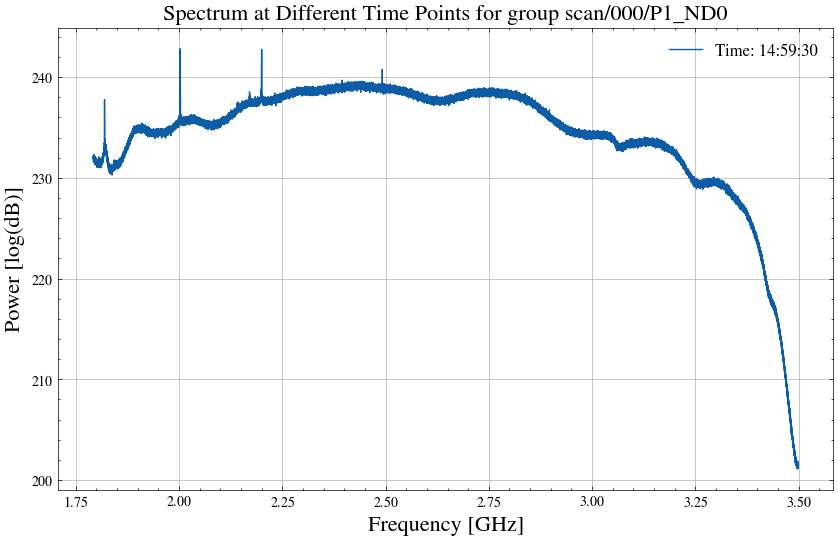

In [16]:
time_source = pd.to_datetime(["2023-03-11 14:59:30+00:00"])
# find nearest time index
moment = time_utc.get_indexer(time_source, method='nearest')
#itime

# #extract the spectrum at the nearest time index

plt.figure(figsize=(10, 6))
for t in moment:
    spectrum_source = spectrum[t, :]
    plt.plot(frequency, spectrum_source, label=f'Time: {time_utc[t].strftime("%H:%M:%S")}')


plt.xlabel('Frequency [GHz]', fontsize=16)
plt.ylabel('Power [log(dB)]', fontsize=16)
plt.title(f'Spectrum at Different Time Points for group {datasets[i].group.values[0]}', fontsize=16)
plt.legend(fontsize=12)
plt.grid()

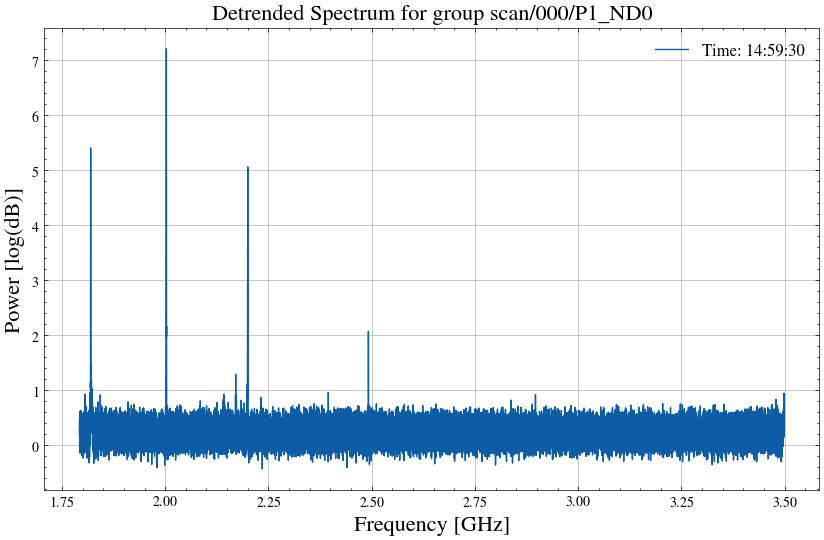

In [17]:
# Detrend the signal

signal_bcorrected = base_correction(frequency, spectrum[moment, :])
plt.figure(figsize=(10, 6))
plt.plot(frequency, signal_bcorrected[0], label=f'Time: {time_utc[moment[0]].strftime("%H:%M:%S")}')

plt.xlabel('Frequency [GHz]', fontsize=16)
plt.ylabel('Power [log(dB)]', fontsize=16)
plt.title(f'Detrended Spectrum for group {datasets[i].group.values[0]}', fontsize=16)

plt.legend(fontsize=12)
plt.grid()

In [18]:
# Isolate the skipe high prominent RFI signals

mask1 = (frequency > 1.8162) & (frequency < 1.8272) # IMT1800 BTX (Cellphone Downlink) GSM 1800
mask2 = (frequency > 1.8735) & (frequency < 1.8737) # IMT1800 BTX (Cellphone Downlink) GSM 1800
mask3 = (frequency > 2.0004) & (frequency < 2.0052) # Mobile Satellite Uplink (Earth to Space)
mask4 = (frequency > 2.0920) & (frequency < 2.0959) # Space Operations (Earth to Space and vice versa)
mask5 = (frequency > 2.1975) & (frequency < 2.2024) # Mobile Satellite Downlink (Space to Earth)
mask6 = (frequency > 2.3605) & (frequency < 2.3658) # Fixed Wireless Access Point to Point/Point to Multipoint #5G
mask7 = (frequency > 2.4916) & (frequency < 2.4925) # Mobile Satellite Services # ITU Resolution 249 (Rev.WRC‑23);
mask8 = (frequency > 2.6250) & (frequency < 2.6250) # ICASA (Independent Communications Authority of South Africa) Frequency Plan ???

mask = mask1 | mask2 | mask3 | mask4 | mask5 | mask6 | mask7 | mask8

In [19]:


mask_signal = signal_bcorrected[0,~mask]

mask_signal.shape, frequency[~mask].shape

((62716,), (62716,))

Text(0.5, 1.0, 'Detrended Spectrum with RFI signals masked ')

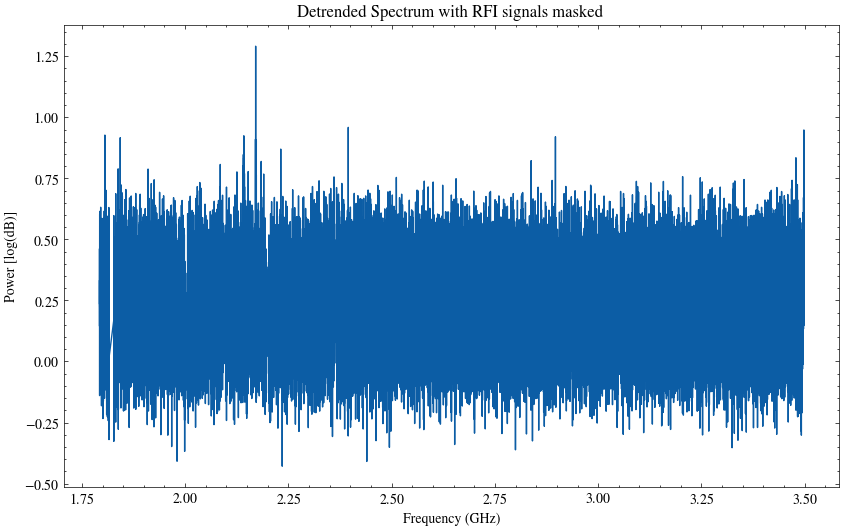

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(frequency[~mask], mask_signal)
plt.xlabel('Frequency (GHz)')
plt.ylabel('Power [log(dB)]')
plt.title(f'Detrended Spectrum with RFI signals masked ')


In [21]:
# perform the satical metrics analysis of the flaged detrended signal
std_mask_det = np.std(mask_signal)
mad_mask_det = MAD(mask_signal)
skew_mask_det = skew(mask_signal)
kurt_mask_det = kurtosis(mask_signal)

print(f"""Standard Deviation of the masked detrended signal: {std_mask_det:.2f}
MAD of the masked detrended signal: {mad_mask_det:.2f}
Skewness of the masked detrended signal: {skew_mask_det:.2f}
Kurtosis of the masked detrended signal: {kurt_mask_det:.2f}""")

Standard Deviation of the masked detrended signal: 0.16
MAD of the masked detrended signal: 0.11
Skewness of the masked detrended signal: 0.01
Kurtosis of the masked detrended signal: 0.04


-> Lest flag the spikes from the spectrum

Text(0.5, 1.0, 'Original Spectrum with RFI signals Flaged ')

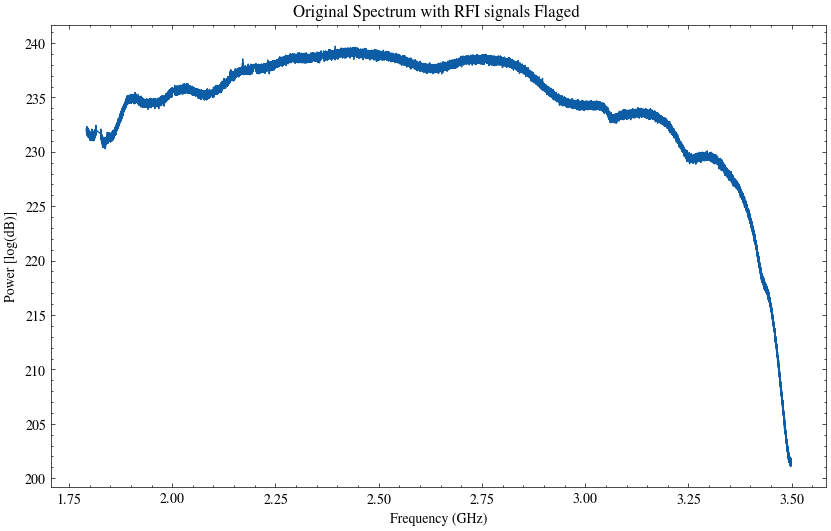

In [22]:
spectrum_source_flag = spectrum_source[~mask]

plt.figure(figsize=(10, 6))
plt.plot(frequency[~mask], spectrum_source_flag)
plt.xlabel('Frequency (GHz)')
plt.ylabel('Power [log(dB)]')
plt.title(f'Original Spectrum with RFI signals Flaged ')

Text(0, 0.5, 'Power [log(dB)]')

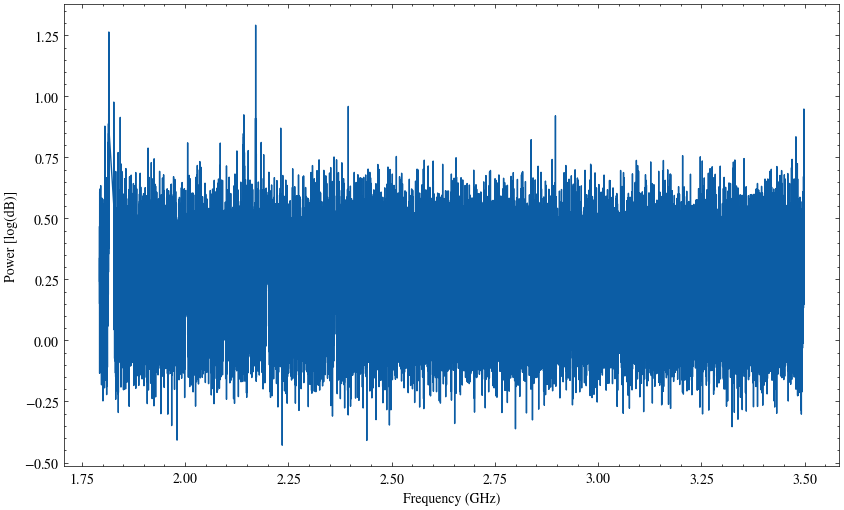

In [23]:
# detrend the spectrum_flaged
detrended_spectrum_flaged = base_correction(frequency[~mask], spectrum_source_flag)
plt.figure(figsize=(10, 6))
plt.plot(frequency[~mask], detrended_spectrum_flaged)
plt.xlabel('Frequency (GHz)')
plt.ylabel('Power [log(dB)]')

In [24]:
# perform the satical metrics analysis 
std_flag_det = np.std(detrended_spectrum_flaged)
mad_flag_det = MAD(detrended_spectrum_flaged)
skew_flag_det = skew(detrended_spectrum_flaged)
kurt_flag_det = kurtosis(detrended_spectrum_flaged)

print(f"""Standard Deviation of the flaged detrended signal: {std_flag_det:.2f}
MAD of the flaged detrended signal: {mad_flag_det:.2f}
Skewness of the flaged detrended signal: {skew_flag_det:.2f}
Kurtosis of the flaged detrended signal: {kurt_flag_det:.2f}""")

Standard Deviation of the flaged detrended signal: 0.16
MAD of the flaged detrended signal: 0.11
Skewness of the flaged detrended signal: 0.06
Kurtosis of the flaged detrended signal: 0.21


->Write the reults in a dataframe to compare

In [25]:
# flag_dataframe=pd.DataFrame({
#     'Std_bef_flag': [std_mask_det],
#     'Std_flag_flag': [std_flag_det],
#     'MAD_bef_flag': [mad_mask_det],
#     'MAD_flag_flag': [mad_flag_det],
#     'Skew_bef_flag': [skew_mask_det],
#     'Skew_flag_flag': [skew_flag_det],
#     'Kurt_bef_flag': [kurt_mask_det],
#     'Kurt_flag_flag': [kurt_flag_det]
# })

# flag_dataframe

In [26]:
flag_dataframe=pd.DataFrame({
    'Std_bef_flag': [std_mask_det],
    'Std_flag_flag': [std_flag_det],
    'MAD_bef_flag': [mad_mask_det],
    'MAD_flag_flag': [mad_flag_det],

})

flag_dataframe

,Std_bef_flag,Std_flag_flag,MAD_bef_flag,MAD_flag_flag
0,0.15788,0.158698,0.106491,0.1063


# Run for the tree different time

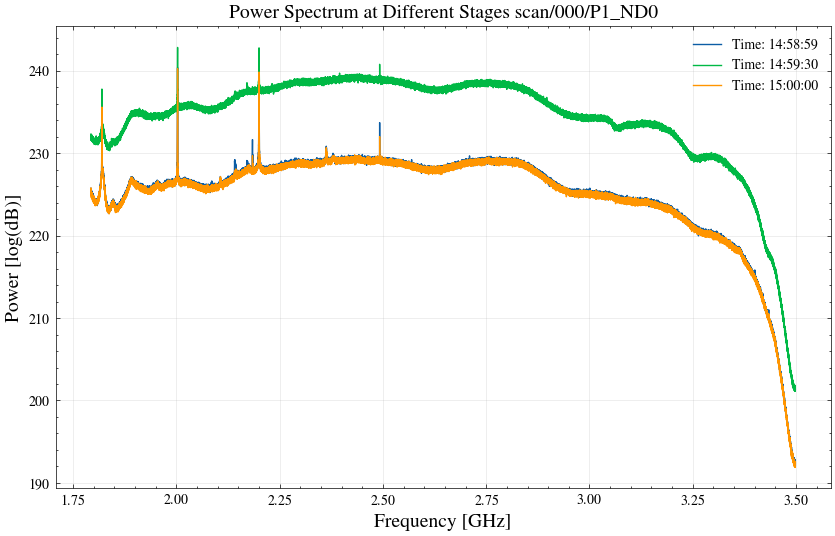

In [27]:
# find nearest time index
itime = time_utc.get_indexer(timebookshelves, method='nearest')
#itime

# #extract the spectrum at the nearest time index

plt.figure(figsize=(10, 6))
for t in itime:
    spectrum_source = spectrum[t, :]
    plt.plot(frequency, spectrum_source, label=f'Time: {time_utc[t].strftime("%H:%M:%S")}')


plt.xlabel('Frequency [GHz]', fontsize=14)
plt.ylabel('Power [log(dB)]', fontsize=14)
plt.title(f'Power Spectrum at Different Stages {datasets[i].group.values[0]}', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

#plt.savefig(f'det_asls_plots/Power_Spectrum_withRFImasked.png', dpi=300, bbox_inches='tight')

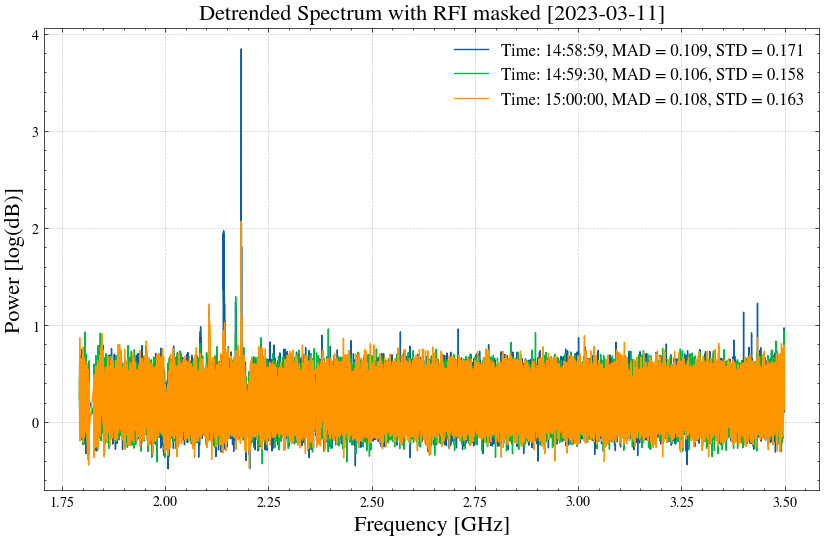

In [28]:
# Detrend the signal
# 
plt.figure(figsize=(10, 6))

for t in itime:
        
    signal_bcorrected_mult = base_correction(frequency, spectrum[t, :])
    plt.plot(frequency[~mask], signal_bcorrected_mult[~mask],
             label=f'Time: {time_utc[t].strftime("%H:%M:%S")},' 
             f' MAD = {MAD(signal_bcorrected_mult[~mask]):.3f},'
             f' STD = {np.std(signal_bcorrected_mult[~mask]):.3f}')

plt.xlabel('Frequency [GHz]', fontsize=16)
plt.ylabel('Power [log(dB)]', fontsize=16)
plt.title(f'Detrended Spectrum with RFI masked [{time_utc[0].strftime("%Y-%m-%d")}]', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#plt.savefig(f'det_asls_plots/Detrended_Spectrum_with_RFI_masked_{time_utc[0].strftime("%Y-%m-%d")}.png', dpi=300, bbox_inches='tight')

In [29]:
# Statical metrics of the detrended signal with RFI signals masked
# perform the satical metrics analysis 

for i in itime:
    signal_bcorrected_mult = base_correction(frequency, spectrum[i, :])
    std_mask_det = np.std(signal_bcorrected_mult[~mask])
    mad_mask_det = MAD(signal_bcorrected_mult[~mask])

    print(f""" 
          Statistical Metrics with RFI masked at Time: {time_utc[i].strftime("%H:%M:%S")}
          Standard Deviation of the masked detrended signal: {std_mask_det:.2f}
          MAD of the masked detrended signal: {mad_mask_det:.2f}
""")


 
          Statistical Metrics with RFI masked at Time: 14:58:59
          Standard Deviation of the masked detrended signal: 0.17
          MAD of the masked detrended signal: 0.11

 
          Statistical Metrics with RFI masked at Time: 14:59:30
          Standard Deviation of the masked detrended signal: 0.16
          MAD of the masked detrended signal: 0.11

 
          Statistical Metrics with RFI masked at Time: 15:00:00
          Standard Deviation of the masked detrended signal: 0.16
          MAD of the masked detrended signal: 0.11



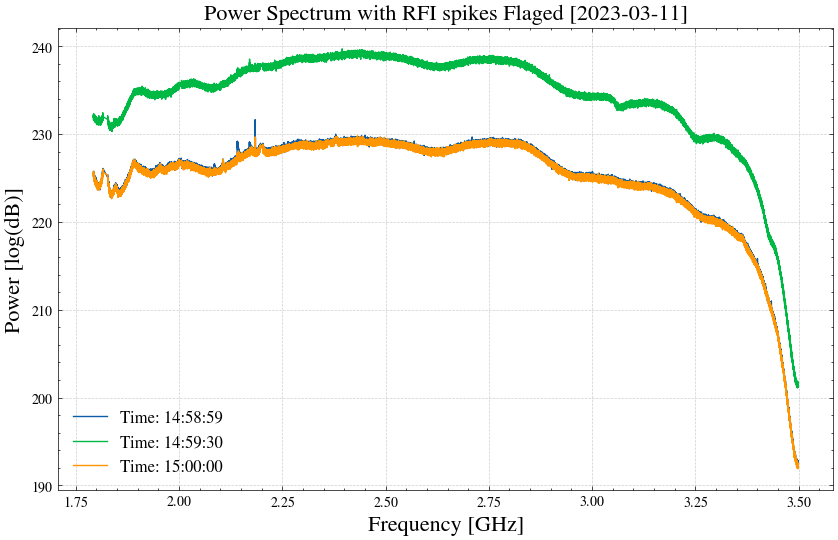

In [30]:

plt.figure(figsize=(10, 6))
for t in itime:
    spectrum_sour_all_flag = spectrum[t, ~mask]
    plt.plot(frequency[~mask], spectrum_sour_all_flag, label=f'Time: {time_utc[t].strftime("%H:%M:%S")}')

plt.title(f'Power Spectrum with RFI spikes Flaged [{time_utc[0].strftime("%Y-%m-%d")}]', fontsize=16)
plt.xlabel('Frequency [GHz]', fontsize=16)
plt.ylabel('Power [log(dB)]', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#plt.savefig(f'det_asls_plots/Power_Spectrum_withRFIFlaged_{time_utc[0].strftime("%Y-%m-%d")}.png', dpi=300, bbox_inches='tight')

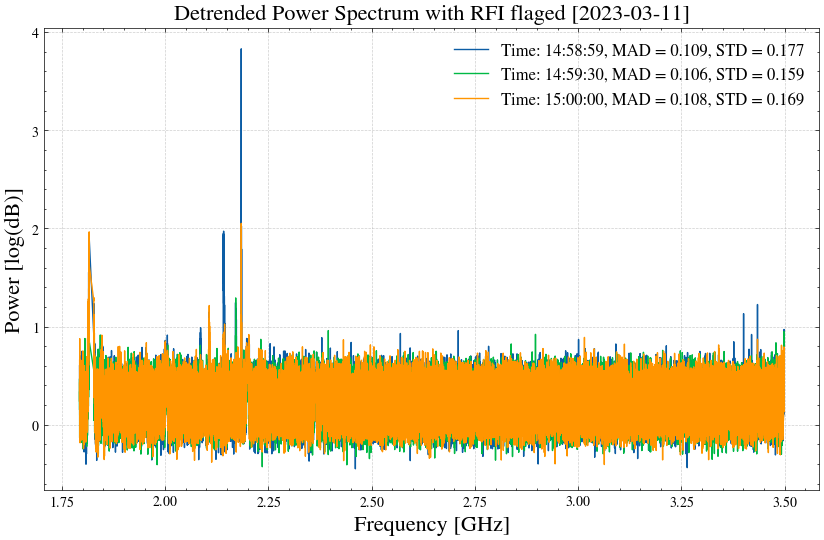

In [31]:
# detrend the spectrum_flaged
plt.figure(figsize=(10, 6))

for t in itime:
    spectrum_sour_all_flag = spectrum[t, ~mask]
    detrended_spectrum_flaged = base_correction(frequency[~mask], spectrum_sour_all_flag)
    plt.plot(frequency[~mask], detrended_spectrum_flaged,
              label=f'Time: {time_utc[t].strftime("%H:%M:%S")},' 
              f' MAD = {MAD(detrended_spectrum_flaged):.3f},'
              f' STD = {np.std(detrended_spectrum_flaged):.3f}')

plt.title(f'Detrended Power Spectrum with RFI flaged [{time_utc[0].strftime("%Y-%m-%d")}]', fontsize=16)
plt.xlabel('Frequency [GHz]', fontsize=16)
plt.ylabel('Power [log(dB)]', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#plt.savefig(f'det_asls_plots/Detre_Power_Spectrum_withRFIFlaged_{time_utc[0].strftime("%Y-%m-%d")}.png', dpi=300, bbox_inches='tight')

In [32]:
# Statical metrics of the detrended signal with RFI signals masked
# perform the satical metrics analysis 

for i in itime:
    spectrum_sour_all_flag = spectrum[i, ~mask]
    detrended_spectrum_flaged = base_correction(frequency[~mask], spectrum_sour_all_flag)
    std_flag_det = np.std(detrended_spectrum_flaged)
    mad_flag_det = MAD(detrended_spectrum_flaged)

    print(f""" 
          Statistical Metrics of signal with RFI flaged at Time: {time_utc[i].strftime("%H:%M:%S")}
          Standard Deviation of the masked detrended signal: {std_flag_det:.2f}
          MAD of the masked detrended signal: {mad_flag_det:.2f}
""")


 
          Statistical Metrics of signal with RFI flaged at Time: 14:58:59
          Standard Deviation of the masked detrended signal: 0.18
          MAD of the masked detrended signal: 0.11

 
          Statistical Metrics of signal with RFI flaged at Time: 14:59:30
          Standard Deviation of the masked detrended signal: 0.16
          MAD of the masked detrended signal: 0.11

 
          Statistical Metrics of signal with RFI flaged at Time: 15:00:00
          Standard Deviation of the masked detrended signal: 0.17
          MAD of the masked detrended signal: 0.11



In [33]:
# Write the both metrecis on a dataframe



# Create empty lists to store the metrics
times = []
std_mask = []
std_flag = []
mad_mask = []
mad_flag = []

# Collect metrics for each time slice
for i in itime:
    signal_bcorrected_mult = base_correction(frequency, spectrum[i, :])
    std_mask_det = np.std(signal_bcorrected_mult[~mask])
    mad_mask_det = MAD(signal_bcorrected_mult[~mask])


    spectrum_sour_all_flag = spectrum[i, ~mask]
    detrended_spectrum_flaged = base_correction(frequency[~mask], spectrum_sour_all_flag)
    std_flag_det = np.std(detrended_spectrum_flaged)
    mad_flag_det = MAD(detrended_spectrum_flaged)

    times.append(time_utc[i].strftime("%H:%M:%S"))
    std_mask.append(std_mask_det)
    mad_mask.append(mad_mask_det)
    std_flag.append(std_flag_det)
    mad_flag.append(mad_flag_det)

# Create a DataFrame with the collected metrics
metrics_df_flaged = pd.DataFrame({
    "Time": times,
    "Std_Mask": std_mask,
    "MAD_Mask": mad_mask,
    "Std_Flagged": std_flag,
    "MAD_Flagged": mad_flag
})

# Display the DataFrame
metrics_df_flaged

,Time,Std_Mask,MAD_Mask,Std_Flagged,MAD_Flagged
0,14:58:59,0.171352,0.108871,0.176783,0.108772
1,14:59:30,0.157880,0.106491,0.158698,0.106300
2,15:00:00,0.163117,0.107956,0.169118,0.108200


/tmp/ipykernel_3143961/98402726.py:51: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax0.legend(fontsize=10)


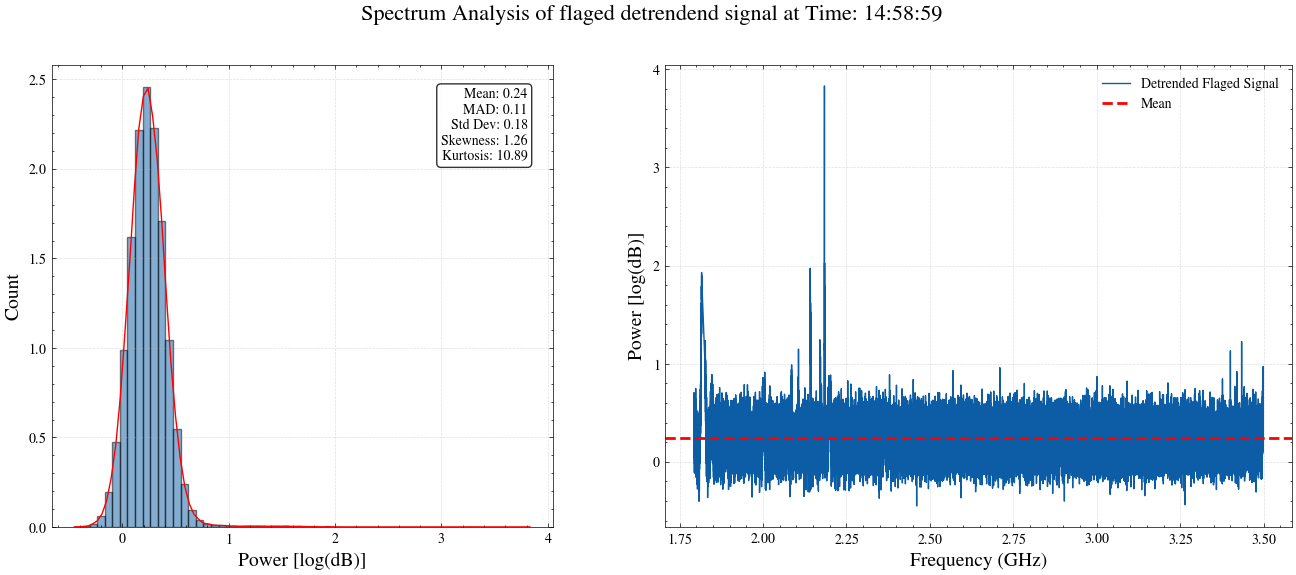

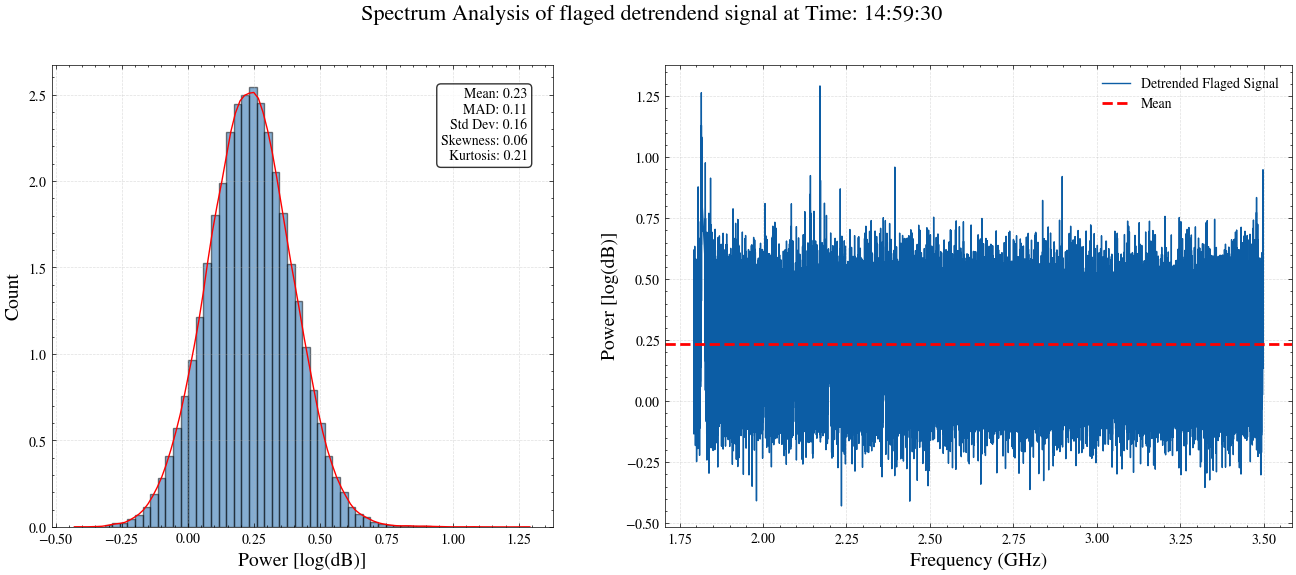

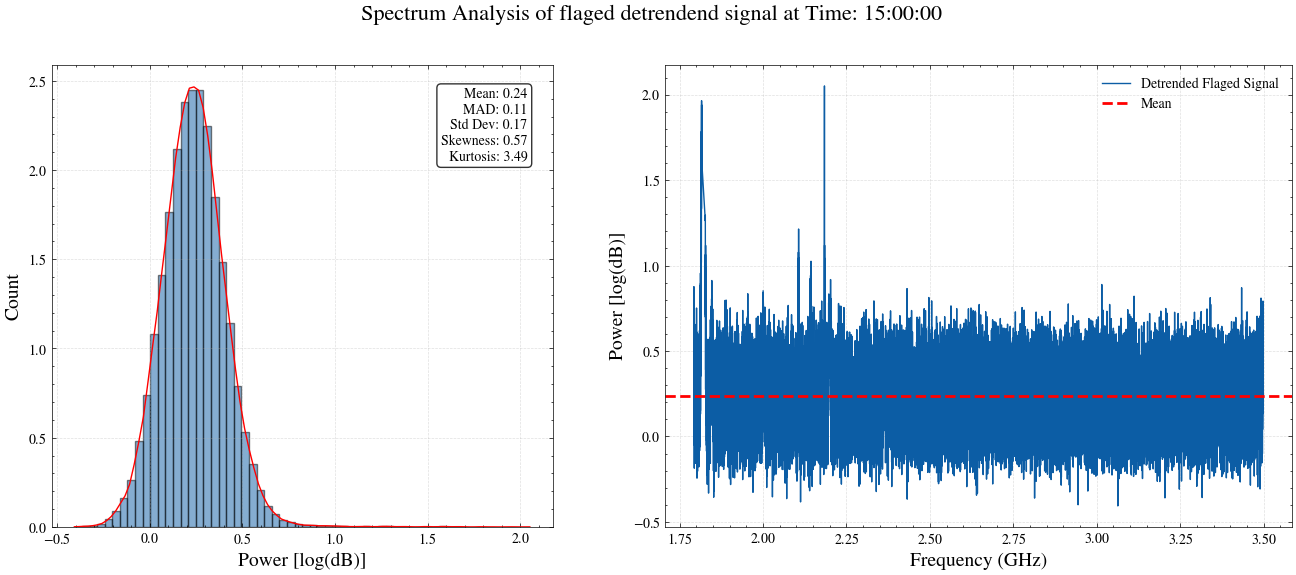

In [34]:
rows = []
for t in itime:

    spectrum_sour_all_flag = spectrum[t, ~mask]
    detrended_spectrum_flaged = base_correction(frequency[~mask], spectrum_sour_all_flag)

    
    #statical parameters
    mean = np.mean(detrended_spectrum_flaged)
    mad = MAD(detrended_spectrum_flaged)
    std_dev = np.std(detrended_spectrum_flaged)
    skewness = skew(detrended_spectrum_flaged)
    kurt = kurtosis(detrended_spectrum_flaged)

    # create a dataframe to hold the statistics
    rows.append({
        'Time': time_utc[t].strftime("%H:%M:%S"),
        'Mean_det': mean,
        'MAD_det': mad,
        'Std Dev_det': std_dev,
        'Skewness_det': skewness,
        'Kurtosis_det': kurt
    })
    stats_df_flag_det = pd.DataFrame(rows)


   

    fig = plt.figure(figsize=(16, 6))
    plt.suptitle(f'Spectrum Analysis of flaged detrendend signal at Time: {time_utc[t].strftime("%H:%M:%S")}', fontsize=16)
    gs = fig.add_gridspec(1, 2, width_ratios=[2, 2.5], 
                          height_ratios=[1], wspace=0.2, hspace=0.3)
    
    stats_text = (f"Mean: {mean:.2f}\n"
                  f"MAD: {mad:.2f}\n"
                  f"Std Dev: {std_dev:.2f}\n"
                  f"Skewness: {skewness:.2f}\n"
                  f"Kurtosis: {kurt:.2f}")
    
     #Kernel Density Estimate
    
    kde = gaussian_kde(detrended_spectrum_flaged)
    x_values = np.linspace(detrended_spectrum_flaged.min(), detrended_spectrum_flaged.max(), 100)
    kde_values = kde(x_values)

    ax0 = fig.add_subplot(gs[0, 0])
    ax0.hist(detrended_spectrum_flaged, bins=60, alpha=0.5, density=True, edgecolor='black')
    ax0.plot(x_values, kde_values, color='red')
    ax0.set_xlabel('Power [log(dB)]', fontsize=14)
    ax0.set_ylabel('Count', fontsize=14)
    ax0.legend(fontsize=10)
    ax0.grid(linestyle='--', alpha=0.4)
    ax0.text(0.95, 0.95, stats_text, transform=ax0.transAxes, fontsize=10,
             verticalalignment='top', horizontalalignment='right',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    ax1 = fig.add_subplot(gs[0, 1])
    ax1.plot(frequency[~mask],detrended_spectrum_flaged, label='Detrended Flaged Signal')
    ax1.axhline(mean, color='r', linestyle='--', linewidth=2, label='Mean')
    ax1.legend(fontsize=10)
    ax1.grid(linestyle='--', alpha=0.4)
    ax1.set_ylabel('Power [log(dB)]',fontsize=14)
    ax1.set_xlabel('Frequency (GHz)', fontsize=14)

# Conclusion of the process

As defined at the beginning of this notebook, the objective was to assess the impact of detrending on RFI identification. From the analysis, we found the following:


1. Baseline variations significantly affect RFI outlier detection.
An increase in baseline variation directly impacts the identification of RFI outliers. This effect is particularly evident during the on-source time interval, where the overall power amplitude increases. As a consequence, the relative amplitude of the RFI emission is reduced, making it more difficult to distinguish low-level RFI from the underlying signal.


2. Masking high-level RFI frequency ranges mask then detrending provides better performance.
The approach in which frequency ranges identified as strong RFI are masked during the detrending process yields improved results. By preventing high-level RFI from influencing the baseline estimation, the detrending becomes more robust. This allows for a more accurate reconstruction of the underlying noise level and enhances the detection of low-level RFI components that would otherwise remain hidden.

